# Main idea

### 1. Calculate local node level TF-IDF 
### 2. Calculate rank correlations between nodes



In [1]:
print('Kernel is alive!')

Kernel is alive!


In [ ]:
import glob
import os
import matplotlib.pyplot as plt
from collections import defaultdict
import pandas as pd
from tqdm import tqdm 
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
from sentence_transformers import SentenceTransformer
# from sklearn.decomposition import PCA
import geopandas as gpd
from time import time

# Create embeddings function

In [ ]:

counties = gpd.read_file(r'county_data.shp')
countyfips= counties.countyfips

In [ ]:
year = '2020'

folder_path = "/tweets_us_" + year
grouped_files = defaultdict(list)

file_paths = glob.glob(os.path.join(folder_path, "*.csv.gz"))

# Group files by day
for file_path in file_paths:
    filename = os.path.basename(file_path)
    day = filename[:10]
    grouped_files[day].append(file_path)

# Update this base path to where your results should go
base_path = "sem_dist_county/"


In [ ]:
#
# sbert embeddings
#


sbert_model = SentenceTransformer('all-MiniLM-L6-v2')  # or another lightweight model

def corr_matrix_bert(freq_dfs_dict, sbert_model, k=10, county_fips=countyfips):
    t1 = time()
    keys_og = list(freq_dfs_dict.keys())

    # Load Sentence-BERT model once
    model = sbert_model 

    # Preprocess: get embedding per county
    embeddings_dict = {}
    for key in (keys_og): # per day
        df = freq_dfs_dict[key]
        if isinstance(df, pd.DataFrame):
            top_terms = df.head(k)['term'].tolist()
            if len(top_terms) >= 2:
                try:
                    embeddings = model.encode(top_terms, convert_to_numpy=True)
                    
                    # Get corresponding weights
                    counts = df.head(k)['count'].to_numpy()
                    weights = counts / counts.sum()  # Normalize weights to sum to 1
                    mean_embedding = np.average(embeddings, axis=0, weights=weights)
                    
                    # store embeddings for later
                    embeddings_dict[key] = mean_embedding
                    
                except Exception as e:
                    print(f"Encoding failed for {key}: {e}")
                    embeddings_dict[key] = None
            else:
                embeddings_dict[key] = None
        else:
            embeddings_dict[key] = None

    # Filter to only valid embeddings
    valid_keys = [k for k in keys_og if embeddings_dict[k] is not None]
    valid_embeddings = np.array([embeddings_dict[k] for k in valid_keys])
    
    # Compute full cosine similarity matrix in one shot
    sim_matrix = cosine_similarity(valid_embeddings)

    # Build full matrix with NaNs for missing keys
    county_fips = [str(el) for el in county_fips]
    full_similarity = pd.DataFrame(np.nan, index=county_fips, columns=county_fips)
    sim_df = pd.DataFrame(sim_matrix, index=valid_keys, columns=valid_keys)
    
    full_similarity.loc[valid_keys, valid_keys] = sim_df
    full_similarity = full_similarity.fillna(0)
    
    #print("Done in", time() - t1, "seconds.")
    return full_similarity


## Understand embedding and correlation functionality

In [ ]:
#
# Basic testing of embedding and correlation functionality
#

countyfips = ["01001", "01003", "01005", "01007"]

freq_dfs_dict = {
    "01001": pd.DataFrame({
        "term": ["covid", "vax", "vaccines", "cases", "trump"],
        "count": [50, 30, 20, 10, 5]
    }),
    "01003": pd.DataFrame({
        "term": ["love", "covid", "vax", "rain", "trump"],
        "count": [60, 40, 25, 15, 10]
    }),
    "01005": pd.DataFrame({
        "term": ["vaccines", "FFP2", "music", "crowd", "night"],
        "count": [45, 35, 20, 15, 10]
    }),
    "01007": pd.DataFrame({
        "term": ["covid19", "vax", "vaccines", "deaths", "trump"],
        "count": [55, 25, 15, 5, 10]
    }),
}

similarity_matrix = corr_matrix_bert(
    freq_dfs_dict=freq_dfs_dict,
    sbert_model=sbert_model,
    k=5,
    county_fips=countyfips
)

print(similarity_matrix)



          01001     01003     01005     01007
01001  1.000000  0.769439  0.664367  0.905977
01003  0.769439  1.000000  0.591046  0.714827
01005  0.664367  0.591046  1.000000  0.603594
01007  0.905977  0.714827  0.603594  1.000000


In [ ]:
(similarity_matrix.values == similarity_matrix.values.T).all()

np.True_

In [11]:
similarity_matrix.values.diagonal()


array([1., 1., 1., 1.])

In [12]:
similarity_matrix.loc["01001", "01007"]  # flood-related counties
similarity_matrix.loc["01001", "01005"]  # flood vs music, should be low


np.float64(0.6643665925475694)

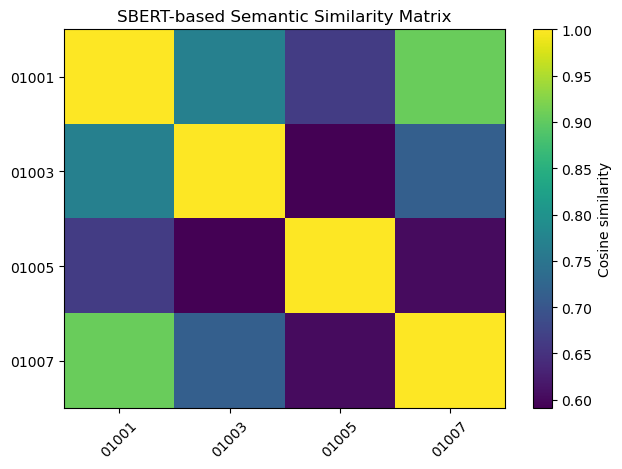

In [ ]:

plt.imshow(similarity_matrix, aspect="auto")
plt.colorbar(label="Cosine similarity")
plt.xticks(range(len(countyfips)), countyfips, rotation=45)
plt.yticks(range(len(countyfips)), countyfips)
plt.title("SBERT-based Semantic Similarity Matrix")
plt.tight_layout()
plt.show()


# Start loading files and create counts

In [ ]:
t1 = time()

lengths = []
import re
import pandas as pd
from collections import Counter
import nltk

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# --- MODIFICATION IS HERE ---
# Add your custom words to the default list
my_stop_words = list(ENGLISH_STOP_WORDS) + ['https','http','think', 'like', 'do','bio','link']

vectorizer = CountVectorizer(
    stop_words=my_stop_words,
    lowercase=True,
    token_pattern=r'\b[a-zA-Z]{2,}\b',  # only alphabetic words of length ≥2
)

# NeW: Dictionary to collect counts per day and per fip
tweet_counts = defaultdict(dict)
freq_dfs_dict = dict()

for day, files in tqdm(grouped_files.items(), desc="Processing grouped days"):
    daily_dfs = []

    for file in files:
        try:
            df = pd.read_csv(file, sep='\t', compression='gzip', dtype='unicode', usecols=["countyfips", "text"])
            daily_dfs.append(df)
        except Exception as e:
            print(f"Error reading {file}: {e}")

    if daily_dfs:
        combined_df = pd.concat(daily_dfs, ignore_index=True)
        combined_df.dropna(subset=["text"], inplace=True)
        combined_df["countyfips"] = combined_df["countyfips"].astype("category")
        
        for fip in (combined_df["countyfips"].unique()):
            df_fip = combined_df[combined_df['countyfips'] == fip]
            texts = df_fip["text"].tolist()
        
            try:
                # Tf-IDF
                X = vectorizer.fit_transform(texts)

                # Count words
                word_counts = X.sum(axis=0).A1
                terms = vectorizer.get_feature_names_out()
                freq_df = pd.DataFrame({'term': terms, 'count': word_counts})
                freq_df = freq_df.sort_values(by='count', ascending=False).reset_index(drop=True)
                terms = list(freq_df.term)
                
                # freq_df = get_word_frequencies_fast(texts)
 
                freq_dfs_dict[fip] = freq_df
            except Exception as Error: 
                freq_dfs_dict[fip] = np.nan
        corr_matrix = corr_matrix_bert(freq_dfs_dict, sbert_model, k=100, county_fips=countyfips)  

        if day.replace('-', '_')[-1] == '_':
            day_string = day.replace('-', '_')
            day_string = day_string[:5] + '0' + day_string[5:-1]
        else: 
            day_string = day.replace('-', '_')
        print(day_string)
        corr_matrix.to_csv(os.path.join(base_path, f"tfidf_embd_dist_top100words{day_string}.csv"))
        


Processing grouped days:   2%|▏         | 6/366 [05:56<6:14:43, 62.45s/it]

In [17]:
# 
# Check whether or not files are missing
#


import os
import re
from datetime import datetime, timedelta

# Updated regex pattern to capture year, month, day
pattern = re.compile(r"tfidf_embd_dist_top100words(\d{4})_(\d{1,2})_(\d{1,2})\.csv")

# Step 1: Extract and normalize all existing file dates
existing_dates = set()

for filename in os.listdir(base_path):
    match = pattern.match(filename)
    if match:
        year, month, day = match.groups()
        try:
            date_obj = datetime(int(year), int(month), int(day))
            normalized_date = date_obj.strftime("%Y-%m-%d")
            existing_dates.add(normalized_date)
        except ValueError:
            print(f"Invalid date found in filename: {filename}")
            continue

# Step 2: Generate all dates for each year and find missing ones
years = [2020, 2021, 2022]
missing_by_year = {}

for year in years:
    date = datetime(year, 1, 1)
    end_date = datetime(year, 12, 31)
    all_days = set()

    while date <= end_date:
        all_days.add(date.strftime("%Y-%m-%d"))
        date += timedelta(days=1)

    missing_days = sorted(all_days - existing_dates)
    missing_by_year[year] = missing_days

# Step 3: Print missing days per year
for year in years:
    print(f"Missing days for {year} ({len(missing_by_year[year])} days):")
    print(missing_by_year[year])
    print()


Missing days for 2020 (0 days):
[]

Missing days for 2021 (2 days):
['2021-08-31', '2021-11-05']

Missing days for 2022 (4 days):
['2022-02-26', '2022-03-01', '2022-04-02', '2022-04-03']

